# 10. Importancia de variables: análisis complementario

Conservar el análisis ya calculado mediante DecisionTreeClassifier y explicar su procedencia sin volver a ajustar modelos.

**Dataset principal:** `data/nuevo_dataset/cardio_train.csv`. Este cuaderno no ejecuta entrenamientos. Los resultados históricos se leen de archivos conservados; no se sustituyen por nuevas ejecuciones.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "data/nuevo_dataset/cardio_train.csv").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
from src.experimento import (
    ORIGINAL, RESULTADOS, VARIABLES, NOMBRES, cargar_datos, reglas_calidad,
    cargar_metricas, comparar_ejecuciones, tabla_configuracion, verificar_configuracion,
    construir_cnn, tabla_modelo, dibujar_arquitectura, guardar_figura_nueva,
    importancia_guardada, resumen_dataset, verificar_predicciones, tensorflow_disponible,
)

## Procedimiento que originó la tabla
Se usó la misma muestra de 15,000, edad en años, exclusión de `id` y `cardio`, división estratificada 80/20 con semilla 42 y `DecisionTreeClassifier(max_depth=5, random_state=42)`. La siguiente función conserva el código de cálculo como documentación reproducible. **No se invoca**: ejecutar este notebook solo lee la importancia existente. El árbol no es un sustituto entrenado para explicar las predicciones de la CNN.

In [2]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split

def procedimiento_original_importancia_no_ejecutado():
    """Solo referencia del cálculo original; no llamar durante esta reorganización."""
    data = cargar_datos(RESULTADOS / "cardio_15000.csv").copy()
    data["age"] /= 365.25
    X, y = data[VARIABLES], data.cardio
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=.20, stratify=y, random_state=42)
    tree = DecisionTreeClassifier(max_depth=5, random_state=42)
    tree.fit(X_train, y_train)
    return pd.DataFrame({"variable": X.columns, "importancia": tree.feature_importances_}).sort_values("importancia", ascending=False)

D:\UNIVERSIDAD\INGENIERIA DE SISTEMAS\400 PAR\METODOLOGIA DE INVESTIGACION\Cardio\resultados\nuevo_experimento\figuras\reorganizacion\importancia_variables_desde_csv.png


10_importancia_variables:celda-3:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


,variable,variable_es,importancia
0,ap_hi,Presión sistólica,0.747432
1,age,Edad,0.151009
2,cholesterol,Colesterol,0.074941
3,weight,Peso,0.010035
4,ap_lo,Presión diastólica,0.008521
5,height,Altura,0.003609
6,gluc,Glucosa,0.002322
7,active,Actividad física,0.001791
8,gender,Sexo,0.000341
9,smoke,Tabaquismo,0.000000


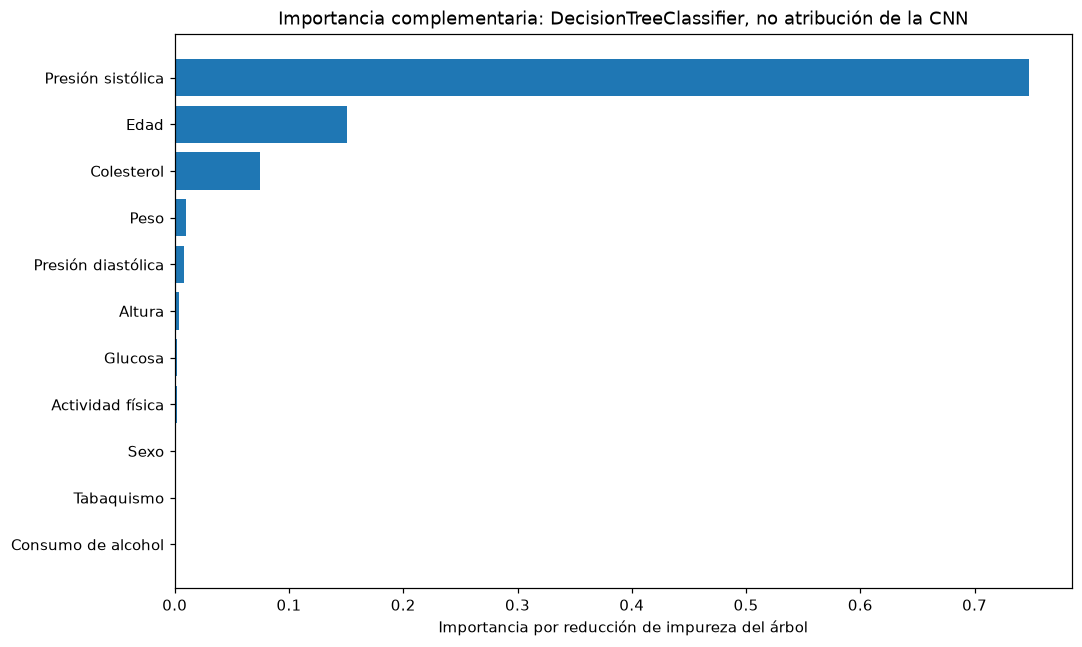

In [3]:
importancia = importancia_guardada()
display(importancia)
assert len(importancia) == 11
assert np.isclose(importancia.importancia.sum(), 1)
fig, ax = plt.subplots(figsize=(10, 6))
orden = importancia.sort_values("importancia")
ax.barh(orden.variable_es, orden.importancia)
ax.set_xlabel("Importancia por reducción de impureza del árbol")
ax.set_title("Importancia complementaria: DecisionTreeClassifier, no atribución de la CNN")
fig.tight_layout()
print(guardar_figura_nueva(fig, "importancia_variables_desde_csv.png"))
plt.show()

Las importancias son del árbol y dependen de su partición y profundidad. No son pesos internos, explicaciones causales ni atribuciones de la CNN. Un valor cero no demuestra irrelevancia clínica. La tabla conserva las variables originales y añade nombres en español para su interpretación.